In [7]:
import os
import torch
import logging
import random
import numpy as np
import scipy.io as scio
from tqdm import tqdm
from torch.utils.data import Dataset
from data import data_api_1 as Data
import model as Model
import argparse
import logging
import core.logger as Logger
import core.metrics as Metrics
import os
from data import dataset
import matplotlib.pyplot as plt
import time

parser = argparse.ArgumentParser()
parser.add_argument('-c', '--config', type=str, default='config/sr_sr3_64_64.json',
                    help='JSON file for configuration')
parser.add_argument('-p', '--phase', type=str, choices=['train', 'val'], 
                    help='Run either train(training) or val(generation)', default='val')
parser.add_argument('-gpu', '--gpu_ids', type=str, default=None)
parser.add_argument('-debug', '-d', action='store_true')
parser.add_argument('-enable_wandb', action='store_true')
parser.add_argument('-log_wandb_ckpt', action='store_true')
parser.add_argument('-log_eval', action='store_true')

args =parser.parse_known_args()[0]
opt = Logger.parse(args)
opt = Logger.dict_to_nonedict(opt)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True

Logger.setup_logger(None, opt['path']['log'],
                    'train', level=logging.INFO, screen=True)
Logger.setup_logger('val', opt['path']['log'], 'val', level=logging.INFO)
logger = logging.getLogger('base')
logger.info(Logger.dict2str(opt))

diffusion = Model.create_model(opt)
logger.info('Initial Model Finished')

current_step = diffusion.begin_step
current_epoch = diffusion.begin_epoch
n_iter = opt['train']['n_iter']

if opt['path']['resume_state']:
    logger.info('Resuming training from epoch: {}, iter: {}.'.format(
        current_epoch, current_step))

diffusion.set_new_noise_schedule(
    opt['model']['beta_schedule'][opt['phase']], schedule_phase=opt['phase'])

26-10-17 04:56:57.725 - INFO:   name: sr_NUSNMR
  phase: val
  gpu_ids: [3]
  path:[
    log: experiments/sr_NUSNMR_261017_045657/logs
    tb_logger: experiments/sr_NUSNMR_261017_045657/tb_logger
    results: experiments/sr_NUSNMR_261017_045657/results
    checkpoint: experiments/sr_NUSNMR_261017_045657/checkpoint
    resume_state: /mnt/DATA1/shaojie/code/Image-Super-Resolution-via-Iterative-Refinement-master/experiments/sr_NUSNMR_260711_201821/checkpoint/I250000_E25
    experiments_root: experiments/sr_NUSNMR_261017_045657
  ]
  datasets:[
    train:[
      name: NUSNMR
      mode: LRHR
      dataroot: ./
      datatype: img
      batch_size: 4
      num_workers: 8
      use_shuffle: True
      data_len: 40000
    ]
    val:[
      name: NUSNMR
      mode: LRHR
      dataroot: ./
      datatype: img
      data_len: 2
    ]
  ]
  model:[
    which_model_G: sr3
    diffusion_module: pnp_2d
    finetune_norm: False
    unet:[
      in_channel: 2
      out_channel: 2
      inner_channel: 

export CUDA_VISIBLE_DEVICES=3


26-10-17 04:56:58.737 - INFO: Loading pretrained model for G [/mnt/DATA1/shaojie/code/Image-Super-Resolution-via-Iterative-Refinement-master/experiments/sr_NUSNMR_260711_201821/checkpoint/I250000_E25] ...
26-10-17 04:56:58.737 - INFO: Loading pretrained model for G [/mnt/DATA1/shaojie/code/Image-Super-Resolution-via-Iterative-Refinement-master/experiments/sr_NUSNMR_260711_201821/checkpoint/I250000_E25] ...
26-10-17 04:56:59.081 - INFO: Model [DDPM] is created.
26-10-17 04:56:59.081 - INFO: Model [DDPM] is created.
26-10-17 04:56:59.085 - INFO: Initial Model Finished
26-10-17 04:56:59.085 - INFO: Initial Model Finished
26-10-17 04:56:59.087 - INFO: Resuming training from epoch: 0, iter: 0.
26-10-17 04:56:59.087 - INFO: Resuming training from epoch: 0, iter: 0.


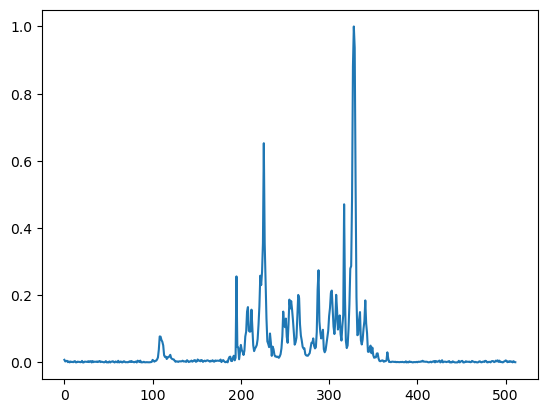

In [ ]:
np.random.seed(60)
def pad_data(data, block_size):
    height, width = data.shape
    pad_height = (block_size - height % block_size) % block_size
    pad_width = (block_size - width % block_size) % block_size
    padded_data = np.pad(data, ((0, pad_height), (0, pad_width)), mode='constant', constant_values=0)
    return padded_data, pad_height, pad_width


def block_data(data, block_size):
    padded_data, pad_height, pad_width = pad_data(data, block_size)
    height, width = padded_data.shape
    num_blocks_vertical = height // block_size
    num_blocks_horizontal = width // block_size
    blocks = np.empty((num_blocks_vertical * num_blocks_horizontal, block_size, block_size), dtype=padded_data.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = padded_data[i*block_size:(i+1)*block_size, j*block_size:(j+1)*block_size]
            blocks[idx] = block
            idx += 1
    return blocks, padded_data.shape, pad_height, pad_width


def reconstruct_data(blocks, pad_shape, pad_height, pad_width):
    height, width = pad_shape
    num_blocks, block_height, block_width = blocks.shape
    num_blocks_vertical = height // block_height
    num_blocks_horizontal = width // block_width
    reconstructed_data = np.empty((height, width), dtype=blocks.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = blocks[idx]
            reconstructed_data[i*block_height:(i+1)*block_height, j*block_width:(j+1)*block_width] = block
            idx += 1
    final_data = reconstructed_data[:height if not pad_height else -pad_height, :width if not pad_width else -pad_width]
    return final_data


data = scio.loadmat('data/Hnoesy_4D.mat')['data']
mask = scio.loadmat('data/Hnoesy_4D_Mask_0.1.mat')['mask']
FID_Ideal = data
N1, N2, N3, num_block = data.shape
N1 = N1 // 2
N2 = N2 // 2
N3 = N3 // 2
N4 = num_block

X_temp = np.zeros((N1, N2, N3, N4))
X1_temp = np.zeros((N1, N2, N3, num_block))
X2_temp = np.zeros((N1, N2, N3, num_block))
X3_temp = np.zeros((N1, N2, N3, num_block))
X4_temp = np.zeros((N1, N2, N3, num_block))
X5_temp = np.zeros((N1, N2, N3, num_block))
X6_temp = np.zeros((N1, N2, N3, num_block))
X7_temp = np.zeros((N1, N2, N3, num_block))
X8_temp = np.zeros((N1, N2, N3, num_block))

F1 = np.squeeze(FID_Ideal[0, 0, 0, :])
F1 = np.abs(F1 / np.max(F1))

plt.figure(1)
plt.plot(F1)


RRR = FID_Ideal[0:2*N1:2, 0:2*N2:2, 0:2*N3:2, F1>0.01]
RIR = FID_Ideal[0:2*N1:2, 1:2*N2:2, 0:2*N3:2, F1>0.01]
IRR = FID_Ideal[1:2*N1:2, 0:2*N2:2, 0:2*N3:2, F1>0.01]
IIR = FID_Ideal[1:2*N1:2, 1:2*N2:2, 0:2*N3:2, F1>0.01]
RRI = FID_Ideal[0:2*N1:2, 0:2*N2:2, 1:2*N3:2, F1>0.01]
RII = FID_Ideal[0:2*N1:2, 1:2*N2:2, 1:2*N3:2, F1>0.01]
IRI = FID_Ideal[1:2*N1:2, 0:2*N2:2, 1:2*N3:2, F1>0.01]
III = FID_Ideal[1:2*N1:2, 1:2*N2:2, 1:2*N3:2, F1>0.01]

fid1 = RRR + 1j*RRI
fid2 = RIR + 1j*RII
fid3 = IRR + 1j*IRI
fid4 = IIR + 1j*III


torch.Size([5, 64, 64])


26-10-17 04:57:00.707 - INFO: Loading pretrained model for G [/mnt/DATA1/shaojie/code/Image-Super-Resolution-via-Iterative-Refinement-master/experiments/sr_NUSNMR_260711_201821/checkpoint/I250000_E25] ...
26-10-17 04:57:00.707 - INFO: Loading pretrained model for G [/mnt/DATA1/shaojie/code/Image-Super-Resolution-via-Iterative-Refinement-master/experiments/sr_NUSNMR_260711_201821/checkpoint/I250000_E25] ...
26-10-17 04:57:00.998 - INFO: Model [DDPM] is created.
26-10-17 04:57:00.998 - INFO: Model [DDPM] is created.
nus3d 2D PnP sampling: 100%|██████████| 100/100 [00:08<00:00, 11.53it/s]


Convergence data saved to: ./convergence_logs/admm_convergence.npz
time(s)   
8.68      


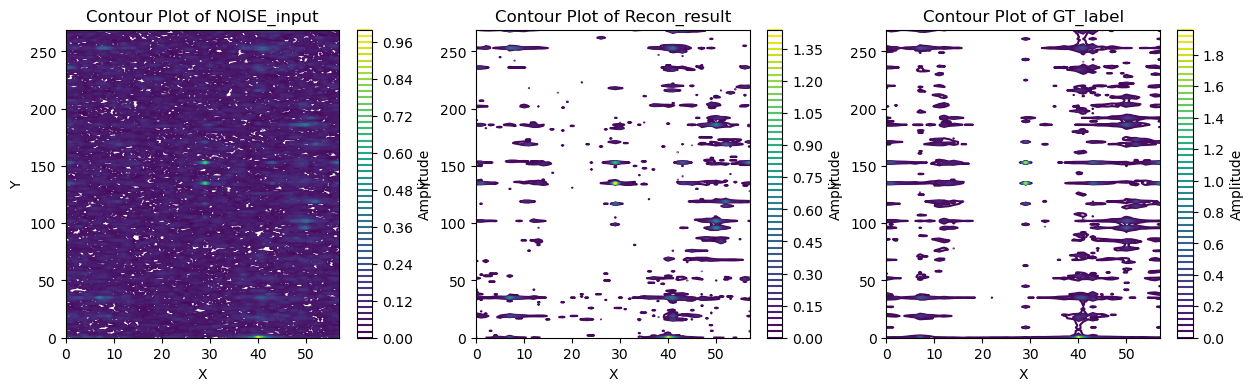

In [ ]:
ori_fid = fid1

U = mask
NUS_FID_all = np.multiply(U[:, :, :, np.newaxis], ori_fid)
NOISE_input_all = np.fft.fftn(NUS_FID_all, axes=(0, 1, 2))
GT_label_all = np.fft.fftn(ori_fid, axes=(0, 1, 2))

NOISE_input = np.sum(NOISE_input_all, axis=3)
GT_label = np.sum(GT_label_all, axis=3)
NUS_FID = np.sum(NUS_FID_all, axis=3)

input_size = 64
NUS_FID, pad_shape, pad_height, pad_width = block_data(NUS_FID.reshape(-1, 58), input_size)
NOISE_input, _, _, _ = block_data(NOISE_input.reshape(-1, 58), input_size)
GT_label, _, _, _ = block_data(GT_label.reshape(-1, 58), input_size)

block_num = GT_label.shape[0]

max_amp = np.max(np.abs(NOISE_input))
NUS_FID = torch.complex(torch.from_numpy(NUS_FID.real).float(), torch.from_numpy(NUS_FID.imag).float()) / (max_amp*4)
NOISE_input = torch.complex(torch.from_numpy(NOISE_input.real).float(), torch.from_numpy(NOISE_input.imag).float()) / (max_amp)
GT_label = torch.complex(torch.from_numpy(GT_label.real).float(), torch.from_numpy(GT_label.imag).float()) / (max_amp* 4)

LR = NUS_FID.unsqueeze(1)
SR = torch.cat((NOISE_input.real.unsqueeze(1), NOISE_input.imag.unsqueeze(1)), dim=1)
HR = torch.cat((GT_label.real.unsqueeze(1), GT_label.imag.unsqueeze(1)), dim=1)
print(GT_label.shape)
val_data = {'LR': LR, 'HR': HR, 'SR': SR}

diffusion = Model.create_model(opt)
avg_mse = 0.0
result_path = '{}/{}'.format(opt['path']['results'], 100)
os.makedirs(result_path, exist_ok=True)
diffusion.set_new_noise_schedule(opt['model']['beta_schedule']['val'], schedule_phase='val')

val_data = diffusion.set_device(val_data)
diffusion.feed_data(val_data)

start = time.time()
diffusion.test(continous=False, pnp_mode='nus3d')
elapsed = time.time() - start

visuals = diffusion.get_current_visuals()
print(f"{'time(s)':<10}")
print(f"{elapsed:<10.2f}")


try:
    if block_num is not None:
        fake_img = reconstruct_data(torch.complex(visuals['INF'][0 : block_num , 0], visuals['INF'][0 : block_num , 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        sr_img = reconstruct_data(torch.complex(visuals['SR'][-block_num : , 0], visuals['SR'][-block_num :, 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        hr_img = reconstruct_data(torch.complex(visuals['HR'][0 : block_num , 0], visuals['HR'][0 : block_num , 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        lr_img = reconstruct_data(visuals['LR'][0 : block_num].squeeze(1).cpu().numpy(), pad_shape, pad_height, pad_width)

except NameError:
    fake_img = torch.complex(visuals['INF'][0, 0], visuals['INF'][0, 1]).squeeze().cpu().numpy()
    sr_img = torch.complex(visuals['SR'][-1, 0], visuals['SR'][-1, 1]).squeeze().cpu().numpy()
    hr_img = torch.complex(visuals['HR'][0, 0], visuals['HR'][0, 1]).squeeze().cpu().numpy()
    lr_img = visuals['LR'][0].squeeze().float().cpu().numpy()


Metrics.plot_contour(
        nus_spec=fake_img,
        recon_spec=sr_img,
        label_spec=hr_img,
        fig_num=2)


rlne= 0.60621923


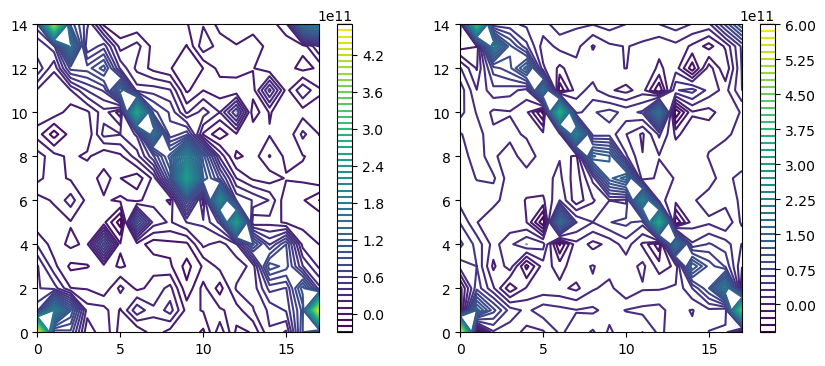

In [10]:
def rlne(recon, ref, eps=1e-12):
    """
    Relative L2-Norm Error (RLNE)

    Parameters
    ----------
    recon : np.ndarray
        Reconstructed data
    ref : np.ndarray
        Reference / ground truth data
    eps : float
        Small value to avoid division by zero

    Returns
    -------
    float
        RLNE value
    """
    recon = np.asarray(recon)
    ref = np.asarray(ref)

    return np.linalg.norm(recon - ref) / (np.linalg.norm(ref) + eps)

recon_spec = sr_img.reshape(15, 18, 58) * (max_amp * 4)
label_spec = hr_img.reshape(15, 18, 58) * (max_amp * 4)
rlne = rlne(recon_spec / np.max(recon_spec), label_spec/ np.max(recon_spec))
print('rlne=', rlne)
plt.figure(1, figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.contour(np.sum(recon_spec, axis=2), 50)
plt.colorbar()
plt.subplot(1, 2, 2)
plt.contour(np.sum(label_spec, axis=2), 50)
plt.colorbar()

FileNotFoundError: [Errno 2] No such file or directory: 'results/recon_spec1_0.1.npy'

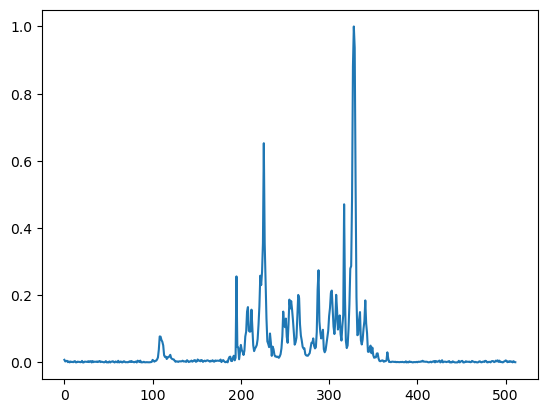

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as scio

def rlne(recon, ref, eps=1e-12):
    """
    Relative L2-Norm Error (RLNE)

    Parameters
    ----------
    recon : np.ndarray
        Reconstructed data
    ref : np.ndarray
        Reference / ground truth data
    eps : float
        Small value to avoid division by zero

    Returns
    -------
    float
        RLNE value
    """
    recon = np.asarray(recon)
    ref = np.asarray(ref)

    return np.linalg.norm(recon - ref) / (np.linalg.norm(ref) + eps)

data = scio.loadmat('data/Hnoesy_4D.mat')['data']
mask = scio.loadmat('data/Hnoesy_4D_Mask_0.15.mat')['mask']
FID_Ideal = data
N1, N2, N3, num_block = data.shape
N1 = N1 // 2
N2 = N2 // 2
N3 = N3 // 2
N4 = num_block

F1 = np.squeeze(FID_Ideal[0, 0, 0, :])
F1 = np.abs(F1 / np.max(F1))

plt.figure(1)
plt.plot(F1)


RRR = FID_Ideal[0:2*N1:2, 0:2*N2:2, 0:2*N3:2, F1>0.01]
RIR = FID_Ideal[0:2*N1:2, 1:2*N2:2, 0:2*N3:2, F1>0.01]
IRR = FID_Ideal[1:2*N1:2, 0:2*N2:2, 0:2*N3:2, F1>0.01]
IIR = FID_Ideal[1:2*N1:2, 1:2*N2:2, 0:2*N3:2, F1>0.01]
RRI = FID_Ideal[0:2*N1:2, 0:2*N2:2, 1:2*N3:2, F1>0.01]
RII = FID_Ideal[0:2*N1:2, 1:2*N2:2, 1:2*N3:2, F1>0.01]
IRI = FID_Ideal[1:2*N1:2, 0:2*N2:2, 1:2*N3:2, F1>0.01]
III = FID_Ideal[1:2*N1:2, 1:2*N2:2, 1:2*N3:2, F1>0.01]

fid1 = RRR + 1j*RRI
fid2 = RIR + 1j*RII
fid3 = IRR + 1j*IRI
fid4 = IIR + 1j*III

recon_spec1 = np.load('results/recon_spec1_0.1.npy')
recon_spec2 = np.load('results/recon_spec2_0.1.npy')
recon_spec3 = np.load('results/recon_spec3_0.1.npy')
recon_spec4 = np.load('results/recon_spec4_0.1.npy')

label_spec1 = np.fft.fftn(fid1, axes=(0, 1, 2))
label_spec2 = np.fft.fftn(fid2, axes=(0, 1, 2))
label_spec3 = np.fft.fftn(fid3, axes=(0, 1, 2))
label_spec4 = np.fft.fftn(fid4, axes=(0, 1, 2))

recon_fid1 = np.fft.ifftn(recon_spec1, axes=(0, 1, 2))
recon_fid2 = np.fft.ifftn(recon_spec2, axes=(0, 1, 2))
recon_fid3 = np.fft.ifftn(recon_spec3, axes=(0, 1, 2))
recon_fid4 = np.fft.ifftn(recon_spec4, axes=(0, 1, 2))

plt.figure(2, figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.contour(np.sum(np.abs(recon_spec2), axis=(0, 3)), 30)
plt.colorbar()
plt.subplot(1, 2, 2)
plt.contour(np.sum(np.abs(label_spec2), axis=(0, 3)), 30)
plt.colorbar()

YZ_recon = np.sum(np.abs(recon_spec1), axis=(0, 3))
YZ_label = np.sum(np.abs(label_spec1), axis=(0, 3))
rlne1 = rlne(YZ_label / np.max(YZ_label), YZ_recon / np.max(YZ_recon))
rlne2 = rlne(np.sum(np.abs(recon_spec2), axis=(0, 3)), np.sum(np.abs(label_spec2), axis=(0, 3)))
rlne3 = rlne(np.sum(np.abs(recon_spec3), axis=(0, 3)), np.sum(np.abs(label_spec3), axis=(0, 3)))
rlne4 = rlne(np.sum(np.abs(recon_spec4), axis=(0, 3)), np.sum(np.abs(label_spec4), axis=(0, 3)))

print('rlne1=', rlne1)
print('rlne2=', rlne2)
print('rlne3=', rlne3)
print('rlne4=', rlne4)

FID_Recon = np.zeros(FID_Ideal.shape)
FID_Recon[0:2*N1:2, 0:2*N2:2, 0:2*N3:2, F1>0.01] = np.real(recon_fid1)
FID_Recon[0:2*N1:2, 1:2*N2:2, 0:2*N3:2, F1>0.01] = np.real(recon_fid2)
FID_Recon[1:2*N1:2, 0:2*N2:2, 0:2*N3:2, F1>0.01] = np.real(recon_fid3)
FID_Recon[1:2*N1:2, 1:2*N2:2, 0:2*N3:2, F1>0.01] = np.real(recon_fid4)
FID_Recon[0:2*N1:2, 0:2*N2:2, 1:2*N3:2, F1>0.01] = np.imag(recon_fid1)
FID_Recon[0:2*N1:2, 1:2*N2:2, 1:2*N3:2, F1>0.01] = np.imag(recon_fid2)
FID_Recon[1:2*N1:2, 0:2*N2:2, 1:2*N3:2, F1>0.01] = np.imag(recon_fid3)
FID_Recon[1:2*N1:2, 1:2*N2:2, 1:2*N3:2, F1>0.01] = np.imag(recon_fid4)

scio.savemat('results/Hnoesy_4D_Recon_0.1.mat', {'FID': FID_Recon})
